# Lista 10 — Transformers para Classificar o 20 Newsgroups

Na aula anterior usamos uma **LSTM** para classificar o conjunto de dados **20 Newsgroups**

Agora vamos resolver **o mesmo problema com um bloco Transformer** (self-attention) e comparar com a LSTM. A pergunta que guia a lista: *o que muda quando trocamos recorrência por atenção?*

**Como usar:** execute as células na ordem, leia o código com atenção e responda aos exercícios da seção final. Use **Runtime → Change runtime type → GPU** (T4) no Colab para o treino ficar rápido.

## 1. Preliminares

In [38]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from keras import layers
from keras import Sequential
import tensorflow as tf

from sklearn.datasets import fetch_20newsgroups

keras.utils.set_random_seed(42)
print("Keras", keras.__version__)

Keras 3.13.2


In [2]:
max_features = 20000   # tamanho do vocabulário
seq_length   = 30      # número de palavras por post (mesmo valor usado com a LSTM)
batch_size   = 32

In [3]:
import gc
from tensorflow import keras


def limpar_memoria(*objs):
  for obj in objs:
    try:
      del obj
    except NameError:
      pass
  keras.backend.clear_session()
  gc.collect()

## 2. Dados

In [28]:
# Já existe um conjunto designado de "train" e "test"
newsgroups_train = fetch_20newsgroups(subset='train')
newsgroups_test  = fetch_20newsgroups(subset='test')

print(len(newsgroups_train.data), len(newsgroups_test.data))
print(newsgroups_train.target_names)

11314 7532
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


Para transformar texto em inteiros usamos a camada `TextVectorization`. Ela constrói o vocabulário com os textos de treino e converte cada post em uma sequência de `seq_length` inteiros (o índice 0 é o *padding* e o 1 é "palavra desconhecida").

> Observação: aqui o texto é **truncado/preenchido no final**, diferente do `pad_sequences` da aula da LSTM, que guardava as últimas palavras. Mantemos os dois só como detalhe de implementação.

In [29]:
vectorizer = layers.TextVectorization(max_tokens=max_features,
                                      output_sequence_length=seq_length)
vectorizer.adapt(np.array(newsgroups_train.data))

x_train = vectorizer(np.array(newsgroups_train.data)).numpy()
x_test  = vectorizer(np.array(newsgroups_test.data)).numpy()

y_train = np.asarray(newsgroups_train.target)   # rótulos inteiros de 0 a 19
y_test  = np.asarray(newsgroups_test.target)

print(x_train.shape, x_test.shape)
print(x_train[0])

(11314, 30) (7532, 30)
[  14    1 9231   34  205   27   36  254    8   16   78    1   30   68
    4 2587  546 1608   29  256    9   24 1171   25  133   58   39   95
 8350   54]


## 3. O bloco Transformer

Um Transformer *encoder* tem dois ingredientes principais:

1. **Self-attention multi-cabeça:** cada palavra calcula pesos de atenção sobre todas as outras palavras do post e produz uma média ponderada de seus *values*.
2. **Rede feed-forward** aplicada a cada posição, com **conexões residuais** e **normalização de camada** em volta de cada sub-bloco.

Como a atenção não tem noção de ordem, somamos aos embeddings das palavras um **embedding de posição** (aprendido).

In [30]:
class TokenAndPositionEmbedding(layers.Layer):
    """Embedding da palavra + embedding da posição (ambos aprendidos)."""
    def __init__(self, seq_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.seq_length = seq_length
        self.token_emb = layers.Embedding(vocab_size, embed_dim)
        self.pos_emb   = layers.Embedding(seq_length, embed_dim)

    def call(self, x):
        positions = keras.ops.arange(0, self.seq_length)
        return self.token_emb(x) + self.pos_emb(positions)
        #ao inves de usar sen e cos, aprende o melhor vetor posição para cadas pos
        #token_emb volta o embedding da palavra


class TransformerBlock(layers.Layer):
    """Self-attention + feed-forward, cada um com residual e LayerNorm."""
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att  = layers.MultiHeadAttention(num_heads=num_heads,
                                              key_dim=embed_dim // num_heads)
        self.ffn  = keras.Sequential([layers.Dense(ff_dim, activation="relu"),
                                      layers.Dense(embed_dim)])
        self.ln1  = layers.LayerNormalization(epsilon=1e-6)
        self.ln2  = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(rate)
        self.drop2 = layers.Dropout(rate)

    def call(self, x, training=False):
        a = self.att(x, x, training=training)          # query = key = value = x
        x = self.ln1(x + self.drop1(a, training=training))
        f = self.ffn(x)
        return self.ln2(x + self.drop2(f, training=training))

In [33]:
embed_dim = 32   # dimensão dos embeddings
num_heads = 2    # número de cabeças de atenção
ff_dim    = 64   # largura da rede feed-forward

inputs = keras.Input(shape=(seq_length,), dtype="int32")
x = TokenAndPositionEmbedding(seq_length, max_features, embed_dim)(inputs)
x = TransformerBlock(embed_dim, num_heads, ff_dim)(x)
x = layers.GlobalAveragePooling1D()(x)     # média sobre as posições
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(20, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding_1  │ (None, 30, 32)         │       640,960 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 30, 32)         │         8,544 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 650,164 (2.48 MB)

 Trainable params: 650,164 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              metrics=["accuracy"])

t0 = time.time()
history = model.fit(x_train, y_train,
                    batch_size=batch_size,
                    epochs=10,
                    validation_data=(x_test, y_test))
print(f"Tempo de treino: {time.time() - t0:.0f}s")

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.4654 - loss: 2.0025 - val_accuracy: 0.6190 - val_loss: 1.3585
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8741 - loss: 0.4799 - val_accuracy: 0.7151 - val_loss: 1.1018
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9637 - loss: 0.1358 - val_accuracy: 0.7304 - val_loss: 1.1582
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9898 - loss: 0.0476 - val_accuracy: 0.7297 - val_loss: 1.2618
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9955 - loss: 0.0244 - val_accuracy: 0.7289 - val_loss: 1.3968
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9974 - loss: 0.0151 - val_accuracy: 0.7304 - val_loss: 1.4454
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9982 - loss: 0.0110 - val_accuracy: 0.7302 - val_loss: 1.5142
Epoch 8/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9982 - loss: 0.0088 - val_accuracy: 

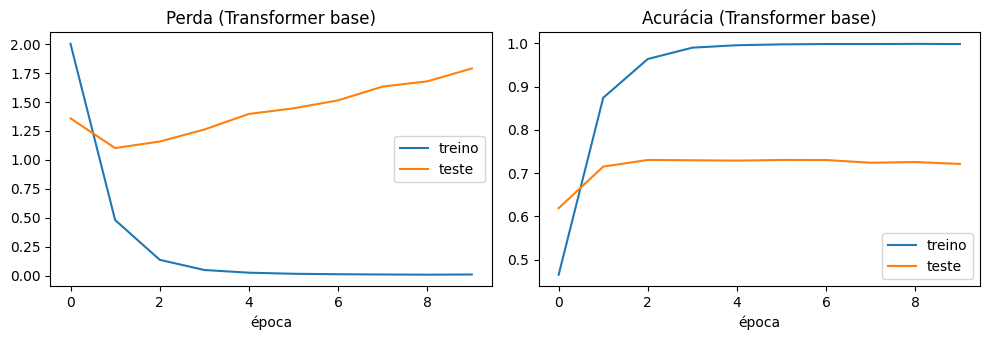

In [35]:
def plot_history(h, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h.history["loss"], label="treino");     ax[0].plot(h.history["val_loss"], label="teste")
    ax[0].set_title(f"Perda {title}");                 ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(h.history["accuracy"], label="treino"); ax[1].plot(h.history["val_accuracy"], label="teste")
    ax[1].set_title(f"Acurácia {title}");              ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(history, "(Transformer base)")

## 4. Olhando os pesos de atenção

A camada `MultiHeadAttention` pode devolver os pesos de atenção com `return_attention_scores=True`. A função abaixo mostra, para um post de teste, **quanto cada palavra (linha) presta atenção em cada outra (coluna)**, em uma das cabeças.

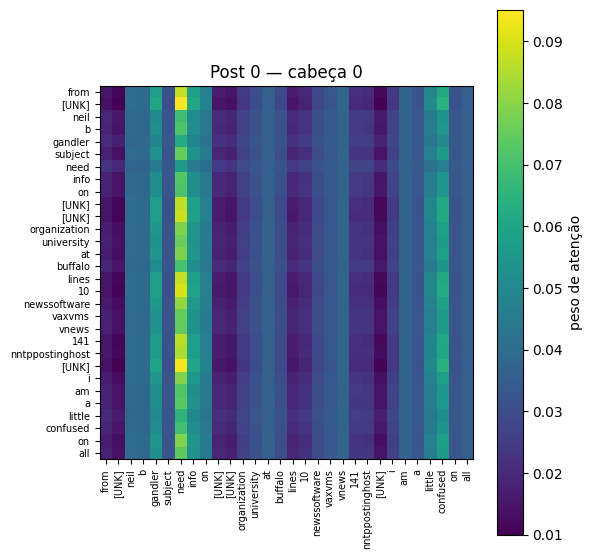

In [36]:
def mostrar_atencao(model, indice_post, cabeca=0):
    bloco = [l for l in model.layers if isinstance(l, TransformerBlock)][0]
    emb   = [l for l in model.layers if isinstance(l, TokenAndPositionEmbedding)][0]

    ids = x_test[indice_post:indice_post + 1]
    e = emb(ids)
    _, pesos = bloco.att(e, e, return_attention_scores=True)   # (1, cabeças, T, T)
    A = keras.ops.convert_to_numpy(pesos)[0, cabeca]

    vocab = vectorizer.get_vocabulary()
    palavras = [vocab[i] for i in ids[0]]

    plt.figure(figsize=(6, 6))
    plt.imshow(A, cmap="viridis")
    plt.xticks(range(len(palavras)), palavras, rotation=90, fontsize=7)
    plt.yticks(range(len(palavras)), palavras, fontsize=7)
    plt.colorbar(label="peso de atenção")
    plt.title(f"Post {indice_post} — cabeça {cabeca}")
    plt.tight_layout(); plt.show()

mostrar_atencao(model, indice_post=0, cabeca=0)

## 5. Exercícios — Sua Vez

Escreva o código e **responda às perguntas em texto** (2 a 4 linhas por pergunta). Sempre compare com a acurácia de teste e o tempo de treino do modelo base acima.


### **Exercício 1 — Transformer × LSTM × SimpleRNN.**
Construa um modelo com uma `LSTM(30)` e outro com uma `SimpleRNN(30)` (mesmos dados, embedding de dimensão 32 treinado, 10 épocas, `Adam(1e-3)`). Monte uma tabela com **número de parâmetros, acurácia de teste e tempo de treino** para os três modelos. Qual é o melhor? Qual é o mais rápido? Há diferenças de *overfitting* nas curvas de treino e teste?

In [11]:
max_features = 20000   # tamanho do vocabulário
seq_length   = 30      # número de palavras por post (mesmo valor usado com a LSTM)
batch_size   = 32
embed_dim = 32   # dimensão dos embeddings
num_heads = 2    # número de cabeças de atenção
ff_dim    = 64   # largura da rede feed-forward

In [12]:
##lstm

model_lstm = Sequential([
    keras.Input(shape=(seq_length,), dtype="int32"),
    layers.Embedding(input_dim=max_features, output_dim=embed_dim),
    layers.LSTM(30),
    layers.Dropout(0.2),
    layers.Dense(20, activation="softmax"),
])

model_lstm.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"],
)

model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30)             │         7,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,180 (2.47 MB)

 Trainable params: 648,180 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
t0 = time.time()
history_lstm = model_lstm.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=10,
    validation_data=(x_test, y_test),
)
print(f"Tempo de treino (LSTM): {time.time() - t0:.0f}s")

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.1174 - loss: 2.6874 - val_accuracy: 0.1484 - val_loss: 2.5579
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.3323 - loss: 1.9341 - val_accuracy: 0.3269 - val_loss: 2.0901
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5286 - loss: 1.4036 - val_accuracy: 0.4100 - val_loss: 1.9884
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6724 - loss: 1.0144 - val_accuracy: 0.4849 - val_loss: 1.8648
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7935 - loss: 0.7259 - val_accuracy: 0.5366 - val_loss: 1.8953
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8634 - loss: 0.5362 - val_accuracy: 0.5511 - val_loss: 1.9124
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8956 - loss: 0.4263 - val_accuracy: 0.5600 - val_loss: 2.0030
Epoch 8/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9258 - loss: 0.3283 - val_accuracy:

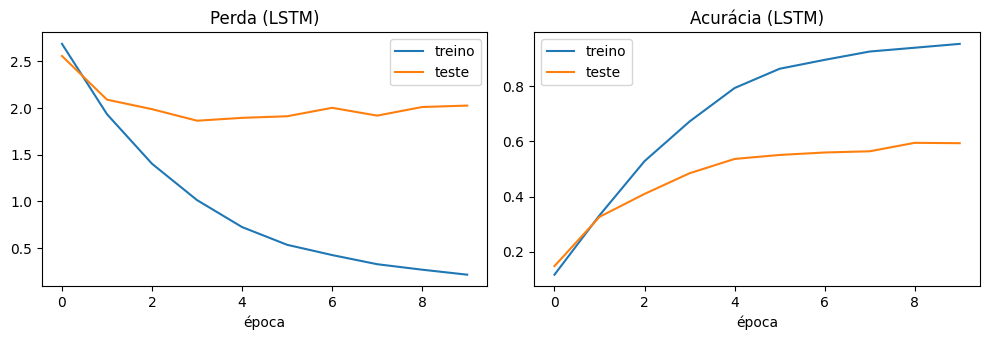

In [14]:
plot_history(history_lstm, "(LSTM)")

In [15]:
model_rnn = keras.Sequential([
    keras.Input(shape=(seq_length,), dtype="int32"),
    layers.Embedding(input_dim=max_features, output_dim=embed_dim),
    layers.SimpleRNN(30),
    layers.Dropout(0.2),
    layers.Dense(20, activation="softmax"),
])

model_rnn.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=["accuracy"],
)

model_rnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 30, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 30)             │         1,890 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642,510 (2.45 MB)

 Trainable params: 642,510 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
t0 = time.time()
history_rnn = model_rnn.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=10,
    validation_data=(x_test, y_test),
)
print(f"Tempo de treino (RNN): {time.time() - t0:.0f}s")

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.2482 - loss: 2.6202 - val_accuracy: 0.3635 - val_loss: 2.3151
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5878 - loss: 1.6167 - val_accuracy: 0.4312 - val_loss: 2.0801
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7464 - loss: 1.0354 - val_accuracy: 0.4529 - val_loss: 2.0793
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8331 - loss: 0.7180 - val_accuracy: 0.4436 - val_loss: 2.2177
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8923 - loss: 0.4944 - val_accuracy: 0.4527 - val_loss: 2.2580
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9228 - loss: 0.3609 - val_accuracy: 0.4526 - val_loss: 2.4035
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9421 - loss: 0.2665 - val_accuracy: 0.4562 - val_loss: 2.4731
Epoch 8/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9632 - loss: 0.1902 - val_accuracy: 

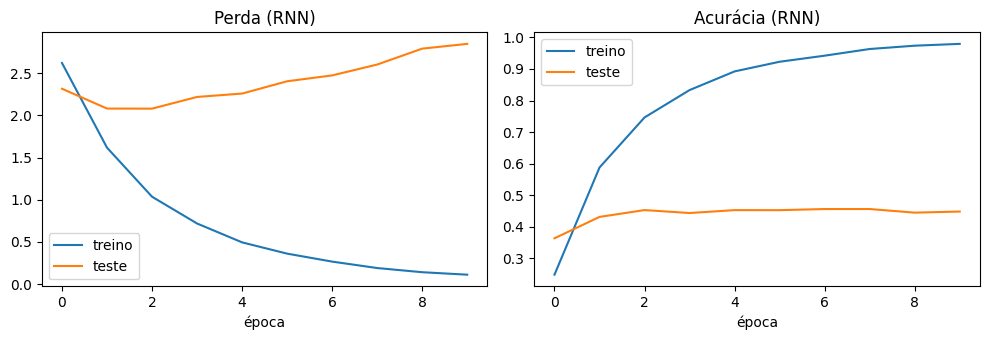

In [17]:
plot_history(history_rnn, "(RNN)")

| Modelo | Parâmetros | Acurácia (`val_accuracy`) | Tempo de treino |
| :--- | :---: | :---: | :---: |
| **Transformer** | 650,164 (2.48 MB) | **0.7215** (72,15%) | **33s** |
| **LSTM(30)** | 648,180 (2.47 MB) | 0.6206 (62,06%) | 43s |
| **SimpleRNN(30)** | 642,510 (2.45 MB) | 0.4515 (45,15%) | 36s |

<b>Respostas</b>

Transformer treina mais rápido e tem mais acurácia, com uma quantidade muito parecida de parâmetros.<br>

Sobre as curvas de treinamento, a rnn é a pior, tendo a maior diferença entre treino e validaão, mostrando o maior overfitting; a lstm tem uma diferença entre treino e teste ( acurácia ) de em torno de 0.3, demonstrando menor overfitting em relação à rnn, isso é ligado ao modelo conseguir atingir maior acurácia; sobre o transformer, ele mantem uma diferença entre treino e validação parecida com a lstm ( um pouco maior até, 0.32 vs 0.35 ), porém, o transformer atinge esse resultado bem mais rápido, convergindo logo para valores que a lstm atingiu ao final do treinamento. isso mostra a capacidade e o potencial que o transformer ainda tem no treinamento.

In [18]:
limpar_memoria(model_lstm, model_rnn, history_rnn, history_lstm)

 ----------- -----------



### **Exercício 2 — A ordem importa?**
Treine o Transformer **sem o embedding de posição** (use apenas `layers.Embedding` para as palavras). O que acontece com a acurácia? Explique, em termos do que a atenção calcula, por que a ordem das palavras pode ou não ser importante para classificar o *tópico* de um post. Em que tarefa a posição seria indispensável?



In [19]:
class TokenEmbedding(layers.Layer):
    """Embedding da palavra sem embedding da posição."""
    def __init__(self, seq_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.seq_length = seq_length
        self.token_emb = layers.Embedding(vocab_size, embed_dim)

    def call(self, x):
        positions = keras.ops.arange(0, self.seq_length)
        return self.token_emb(x)
        #token_emb volta o embedding da palavra


In [20]:
inputs = keras.Input(shape=(seq_length,), dtype="int32")
x = TokenEmbedding(seq_length, max_features, embed_dim)(inputs)
x = TransformerBlock(embed_dim, num_heads, ff_dim)(x)
x = layers.GlobalAveragePooling1D()(x)     # média sobre as posições
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(20, activation="softmax")(x)

model2 = keras.Model(inputs, outputs)
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_embedding                 │ (None, 30, 32)         │       640,000 │
│ (TokenEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 30, 32)         │         8,544 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │           660 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 649,204 (2.48 MB)

 Trainable params: 649,204 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model2.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              metrics=["accuracy"])

t0 = time.time()
history_sem_posicao = model2.fit(x_train, y_train,
                    batch_size=batch_size,
                    epochs=10,
                    validation_data=(x_test, y_test))
print(f"Tempo de treino: {time.time() - t0:.0f}s")

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.4890 - loss: 1.9163 - val_accuracy: 0.6336 - val_loss: 1.3145
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8710 - loss: 0.4797 - val_accuracy: 0.6982 - val_loss: 1.1527
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9654 - loss: 0.1377 - val_accuracy: 0.7054 - val_loss: 1.2546
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9890 - loss: 0.0522 - val_accuracy: 0.7237 - val_loss: 1.3125
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9957 - loss: 0.0251 - val_accuracy: 0.7224 - val_loss: 1.3777
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9974 - loss: 0.0151 - val_accuracy: 0.7221 - val_loss: 1.4412
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9979 - loss: 0.0102 - val_accuracy: 0.7187 - val_loss: 1.5578
Epoch 8/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9983 - loss: 0.0087 - val_accuracy: 

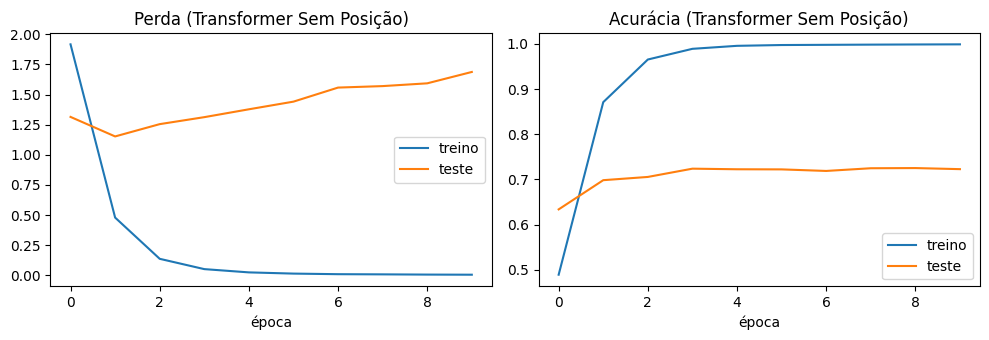

In [22]:
plot_history(history_sem_posicao, "(Transformer Sem Posição)")

**Resposta**

ficou extremamente parecido. a atenção checa a similaridade entre queries e keys das palavras, ou seja, ver a relação e ligação das palavras no contexto da frase. sem os embeddings de posição, vira várias palavras que são correlacionadas pelo modelo, assim, no caso do post, ele consegue encontrar palavras chave, mesmo sem a ordem ( e as palavras chave são um método muito bom para classificar ). em um caso de tradução ( como o proprio transformer original ), a ordem é importante, pois, na sintaxe das frases, ordem importa; na classificação de sentimento, é imporante a ordem, pois uma frase pode ter 'não' e 'bom', assim, não seria satisfatório usar as palavras chave.

In [23]:
limpar_memoria(history_sem_posicao, model2, inputs, x, outputs)



---




### **Exercício 3 — Hiperparâmetros.**
Varie, um de cada vez, (a) `num_heads` (1, 2, 4, 8), (b) `embed_dim` (16, 32, 64), (c) `seq_length` (30, 100, 200) e (d) o número de blocos Transformer empilhados (1, 2, 4). Mostre os resultados em tabela ou gráfico. Você consegue melhorar o modelo base? O que mais ajudou? O que aconteceu com o tempo de treino quando `seq_length` cresceu (lembre-se do custo da atenção, que cresce com T²)?


In [24]:

def rodar_experimento(seq_len=seq_length,dim=embed_dim,heads=num_heads,
ff=ff_dim,num_blocks=1,epochs=10,x_tr=None,x_te=None,):

  inputs = keras.Input(shape=(seq_len,), dtype="int32")
  x = TokenAndPositionEmbedding(seq_len, max_features, dim)(inputs)

  for _ in range(num_blocks):
    x = TransformerBlock(dim, heads, ff)(x)

  x = layers.GlobalAveragePooling1D()(x)
  x = layers.Dropout(0.2)(x)
  outputs = layers.Dense(20, activation="softmax")(x)

  model = keras.Model(inputs, outputs)
  model.compile(
      loss="sparse_categorical_crossentropy",
      optimizer=keras.optimizers.Adam(learning_rate=1e-3),
      metrics=["accuracy"],
  )

  t0 = time.time()
  history = model.fit(
      x_train,
      y_train,
      batch_size=batch_size,
      epochs=epochs,
      validation_data=(x_test, y_test),
      verbose=0,
  )
  tempo = time.time() - t0

  loss_teste, acc_teste = model.evaluate(x_test, y_test, verbose=0)
  acc_treino = history.history["accuracy"][-1]
  params = model.count_params()

  print(f"params={params:,} | acc_treino={acc_treino:.4f} |")
  print(f" acc_teste={acc_teste:.4f} | tempo={tempo:.1f}s")

  return model, history


num_heads=1 -> params=650,164 | acc_treino=0.9987 |
 acc_teste=0.7248 | tempo=33.7s




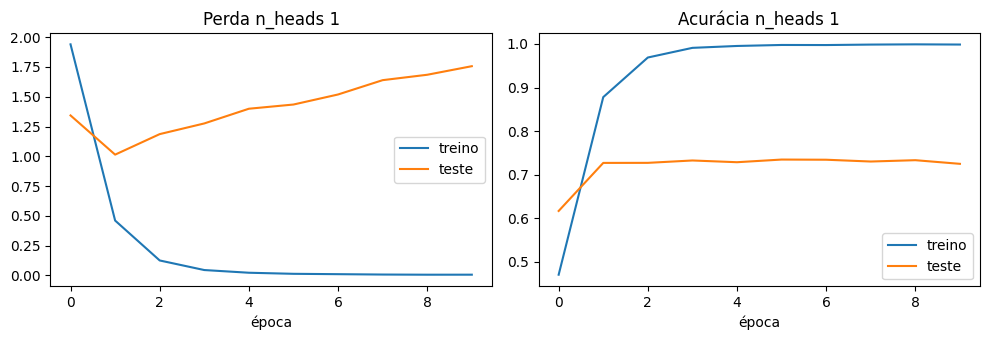



num_heads=2 -> params=650,164 | acc_treino=0.9989 |
 acc_teste=0.7179 | tempo=39.7s




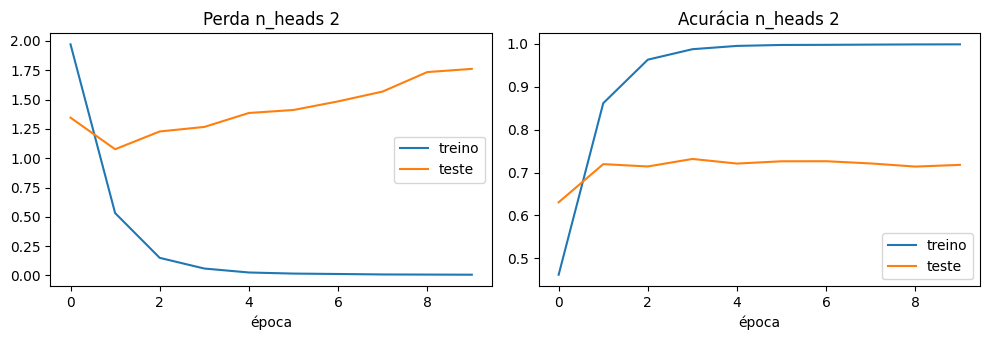



num_heads=4 -> params=650,164 | acc_treino=0.9984 |
 acc_teste=0.7063 | tempo=34.9s




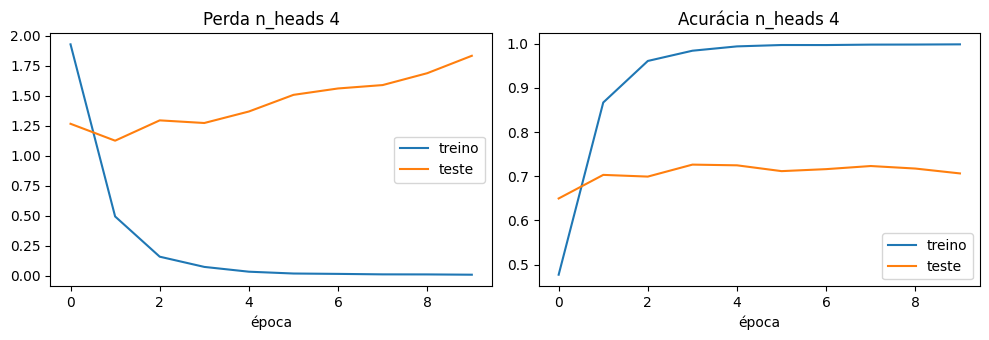



num_heads=8 -> params=650,164 | acc_treino=0.9981 |
 acc_teste=0.7203 | tempo=34.5s




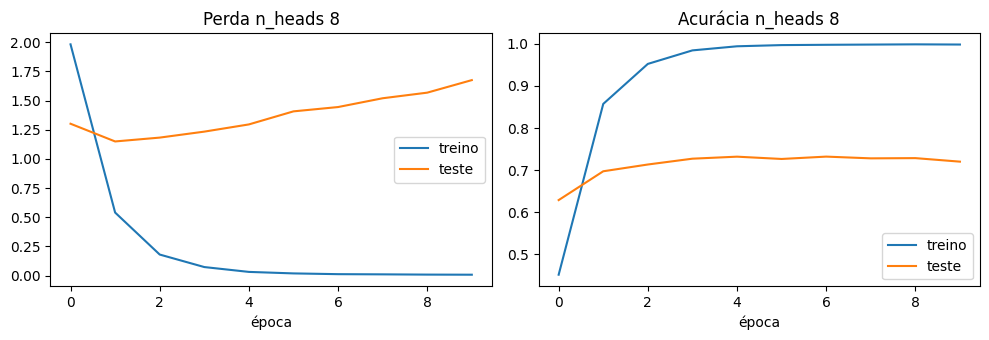

In [25]:
for h in [1, 2, 4, 8]:
  print(f"num_heads={h} -> ", end="")
  _ , history = rodar_experimento(heads=h)
  print("\n")
  plot_history(history, f'n_heads {h}')
  print("\n")



embed_dim=16 -> params=323,044 | acc_treino=0.9943 |
 acc_teste=0.6920 | tempo=38.1s




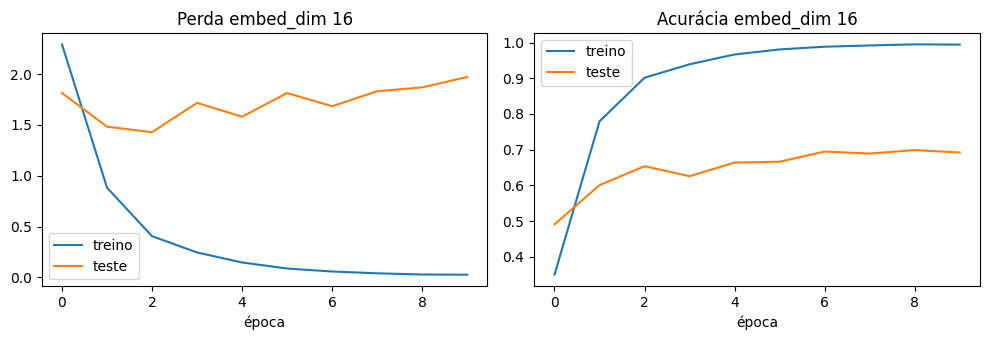



embed_dim=32 -> params=650,164 | acc_treino=0.9980 |
 acc_teste=0.7285 | tempo=31.6s




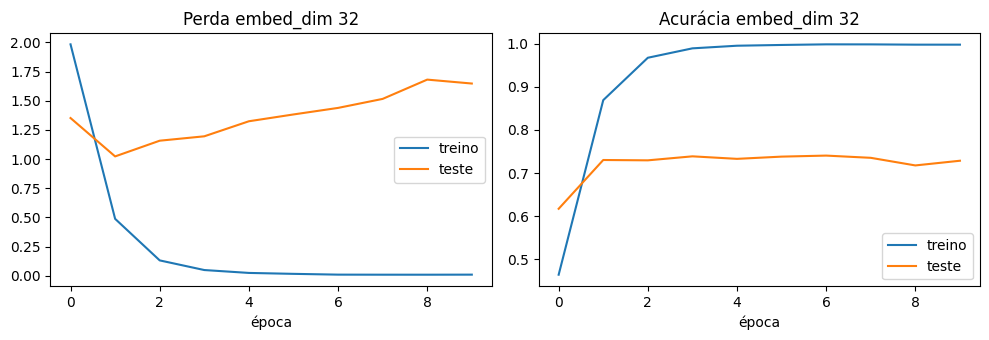



embed_dim=64 -> params=1,316,692 | acc_treino=0.9969 |
 acc_teste=0.6972 | tempo=38.3s




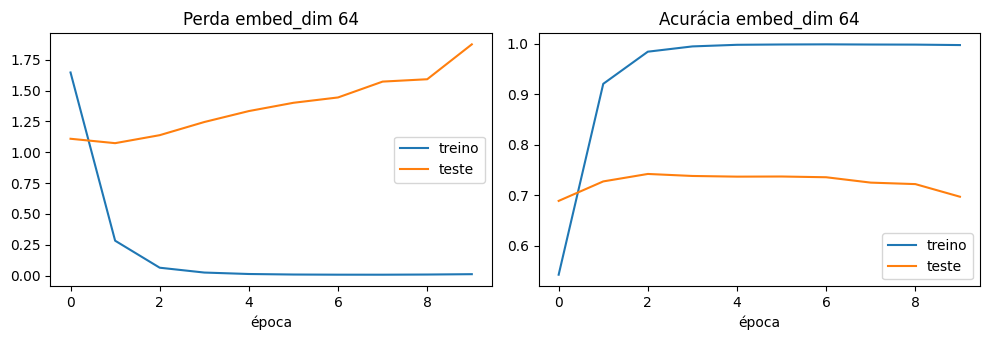

In [26]:
#embed_dim: 16, 32, 64 (ajustando ff_dim proporcionalmente: 2 * dim)
for d in [16, 32, 64]:
  print(f"embed_dim={d} -> ", end="")
  _, history = rodar_experimento(dim=d, ff=d * 2)
  print("\n")
  plot_history(history, f"embed_dim {d}")
  print("\n")

num_blocks=1 -> params=650,164 | acc_treino=0.9971 |
 acc_teste=0.7175 | tempo=30.6s




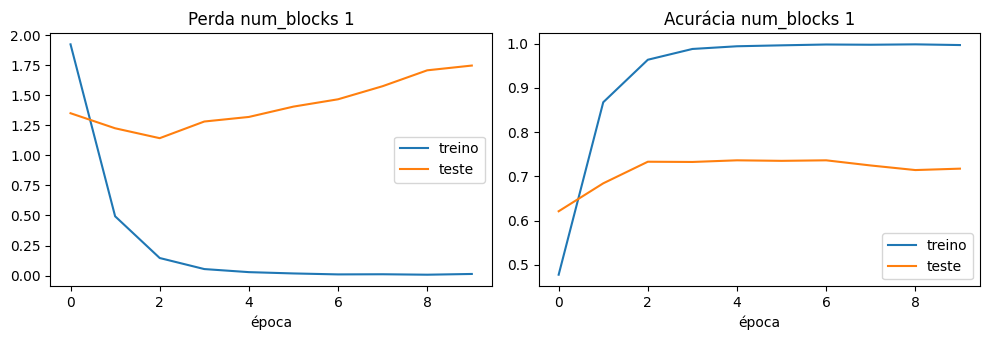



num_blocks=2 -> params=658,708 | acc_treino=0.9966 |
 acc_teste=0.7091 | tempo=42.0s




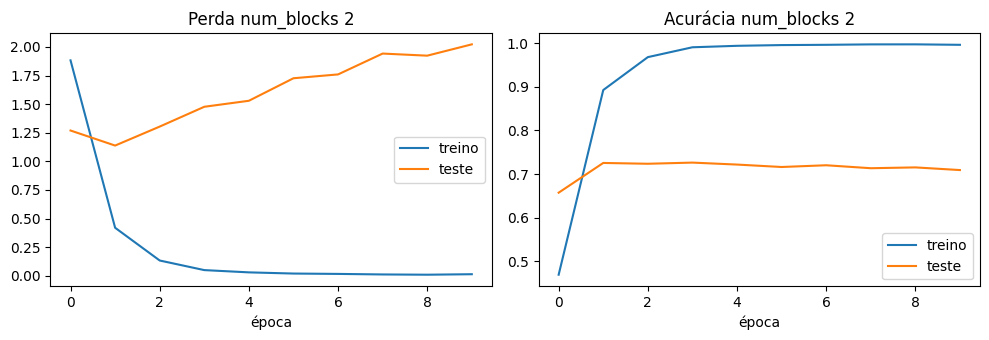



num_blocks=4 -> params=675,796 | acc_treino=0.9865 |
 acc_teste=0.6718 | tempo=56.7s




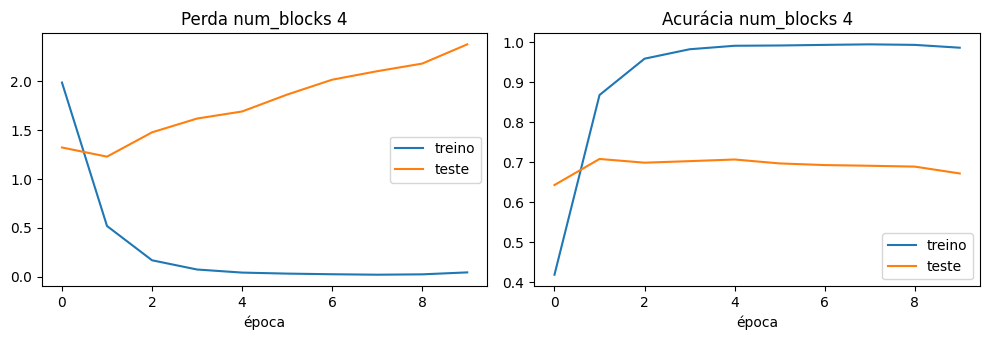

In [27]:
for b in [1, 2, 4]:
  print(f"num_blocks={b} -> ", end="")
  _, history = rodar_experimento(num_blocks=b)
  print("\n")
  plot_history(history, f"num_blocks {b}")
  print("\n")

In [56]:
import numpy as np

def vetorizar_em_lotes(
    vectorizer_base, textos, seq_len, max_tokens, batch_size_vec=1024
):
  vec = layers.TextVectorization(
      max_tokens=max_tokens, output_sequence_length=seq_len
  )
  vec.set_vocabulary(vectorizer_base.get_vocabulary())

  partes = []
  for i in range(0, len(textos), batch_size_vec):
    lote = textos[i : i + batch_size_vec]
    partes.append(vec(lote).numpy())

  del vec
  gc.collect()
  return np.vstack(partes)

In [29]:
#criando uma segunda função de experimento pra conseguir usar
#os diferentes seq_lenght

#sem essa função de cima, a memória estourava...
#tive que ficar apagando os objetos e processar os posts em lote

def rodar_experimento_novo_seq(seq_len,dim=embed_dim,heads=num_heads,
ff=ff_dim,num_blocks=1,epochs=10):

  x_train_s = vetorizar_em_lotes(
      vectorizer, newsgroups_train.data, seq_len, max_features
  )
  x_test_s = vetorizar_em_lotes(
      vectorizer, newsgroups_test.data, seq_len, max_features
  )

  inputs = keras.Input(shape=(seq_len,), dtype="int32")
  x = TokenAndPositionEmbedding(seq_len, max_features, dim)(inputs)

  for _ in range(num_blocks):
    x = TransformerBlock(dim, heads, ff)(x)

  x = layers.GlobalAveragePooling1D()(x)
  x = layers.Dropout(0.2)(x)
  outputs = layers.Dense(20, activation="softmax")(x)

  model = keras.Model(inputs, outputs)
  model.compile(
      loss="sparse_categorical_crossentropy",
      optimizer=keras.optimizers.Adam(learning_rate=1e-3),
      metrics=["accuracy"],
  )

  t0 = time.time()
  history = model.fit(
      x_train_s,
      y_train,
      batch_size=batch_size,
      epochs=epochs,
      validation_data=(x_test_s, y_test),
      verbose=0,
  )
  tempo = time.time() - t0

  _, acc_teste = model.evaluate(x_test_s, y_test, verbose=0)
  acc_treino = history.history["accuracy"][-1]
  params = model.count_params()

  del x_train_s, x_test_s
  gc.collect()

  print(
      f"params={params:,} | acc_treino={acc_treino:.4f} | "
      f"acc_teste={acc_teste:.4f} | tempo={tempo:.1f}s"
  )

  return history, model

seq_length=30 -> params=650,164 | acc_treino=0.9987 | acc_teste=0.7185 | tempo=32.8s




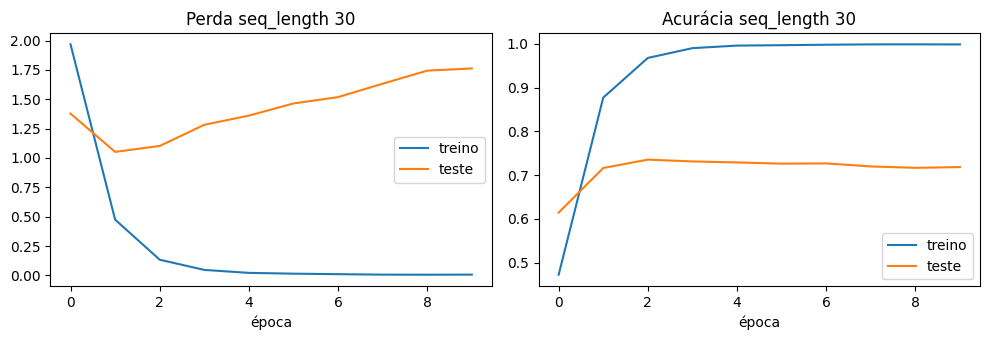



seq_length=100 -> params=652,404 | acc_treino=0.9987 | acc_teste=0.7921 | tempo=64.6s




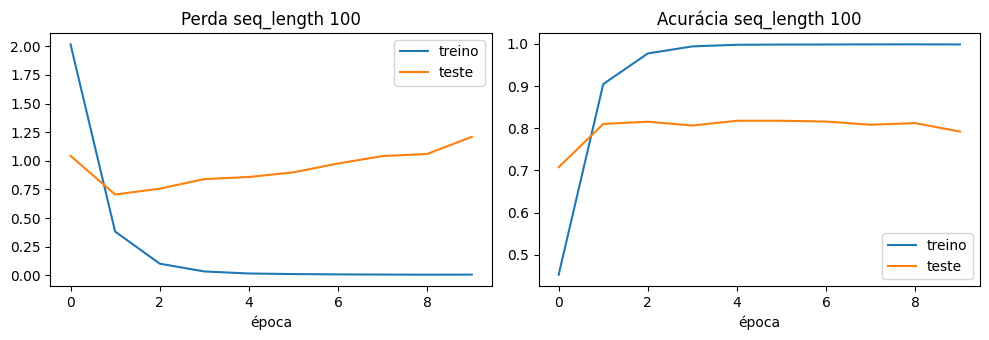



seq_length=200 -> params=655,604 | acc_treino=0.9990 | acc_teste=0.8281 | tempo=42.3s




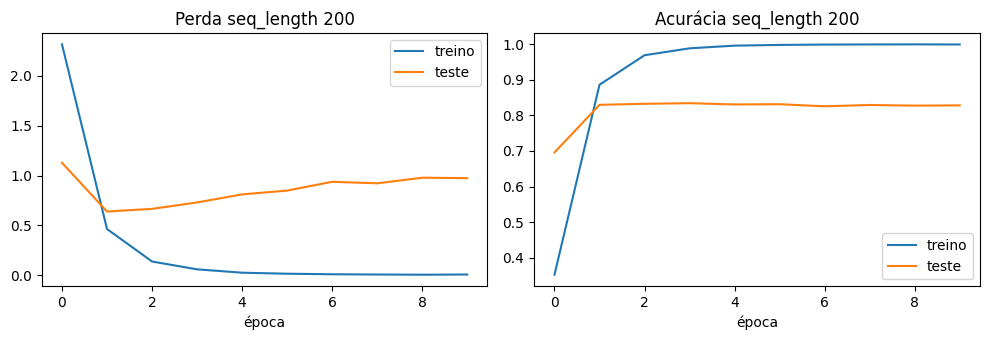

In [30]:
import gc

for s in [30, 100, 200]:
  print(f"seq_length={s} -> ", end="")
  history, model = rodar_experimento_novo_seq(seq_len=s)
  print("\n")
  plot_history(history, f"seq_length {s}")
  print("\n")

  del history, model
  keras.backend.clear_session()
  gc.collect()

 (a) num_heads (1, 2, 4, 8)

| `num_heads` | Parâmetros | Acc Treino | Acc Teste | Tempo |
| :--- | :---: | :---: | :---: | :---: |
| `1` | 650,164 | 0.9987 | 0.7248 | 33.7s |
| `2` | 650,164 | 0.9989 | 0.7179 | 39.7s |
| `4` | 650,164 | 0.9984 | 0.7063 | 34.9s |
| `8` | 650,164 | 0.9981 | 0.7203 | 34.5s |

 (b) embed_dim (16, 32, 64)

| `embed_dim` | Parâmetros | Acc Treino | Acc Teste | Tempo |
| :--- | :---: | :---: | :---: | :---: |
| `16` | 323,044 | 0.9943 | 0.6920 | 38.1s |
| `32` | 650,164 | 0.9980 | 0.7285 | 31.6s |
| `64` | 1,316,692 | 0.9969 | 0.6972 | 38.3s |

 (c) seq_length (30, 100, 200)

| `seq_length` | Parâmetros | Acc Treino | Acc Teste | Tempo |
| :--- | :---: | :---: | :---: | :---: |
| `30` | 650,164 | 0.9987 | 0.7185 | 32.8s |
| `100` | 652,404 | 0.9987 | 0.7921 | 64.6s |
| `200` | 655,604 | 0.9990 | 0.8281 | 42.3s |

 (d) num_blocks (1, 2, 4)

| `num_blocks` | Parâmetros | Acc Treino | Acc Teste | Tempo |
| :--- | :---: | :---: | :---: | :---: |
| `1` | 650,164 | 0.9971 | 0.7175 | 30.6s |
| `2` | 658,708 | 0.9966 | 0.7091 | 42.0s |
| `4` | 675,796 | 0.9865 | 0.6718 | 56.7s |

com base nas tabelas, os melhores desempenhos são a) 1/8 (ambos bem parecidos);<br> b) 32, com mais folga;<br> c) seq lenght 200;<br> d) 1 bloco, sem muita diferença pra 2.<br> eu testaria as combinações com esse valores caso quissese achar o melhor possível. o que mais ajudou foi seq lenght de longe, o que faz muito sentido, é o objetivo do transformers e posts cada vez mais completos podem carregar mais palavras chave e contexto. mas o tempo aumentou bastante também... por algum motivo 200 ta mais rapido que 100(algo sobre a gpu do ambiente), mas o tempo aumenta claramente em relação a 30. por exemplo, a atenção T com 30 tem 900 entradas, com 100, 10⁴ emtradas, e com 200, 4.10⁴ entradas, isso mostra a diferença do tempo



---





### **Exercício 4 — Interpretando a atenção.**
Usando `mostrar_atencao`, observe 3 posts de teste (escolha pelo menos um que o modelo acerta e um que erra) e compare **duas cabeças** diferentes. As cabeças parecem olhar para coisas diferentes (palavras vizinhas, palavras específicas, a própria palavra)? Os pesos de atenção "explicam" a decisão do modelo? Cuidado com conclusões fortes: discuta o que a atenção pode e o que não pode dizer.


In [24]:
previsoes = model.predict(x_test, verbose=0)
classes = np.argmax(previsoes, axis=1)

print(previsoes[0], "\n")
print(classes[0], "\n")

acertos = np.where(classes == y_test)[0]
erros = np.where(classes != y_test)[0]

print("Exemplo acerto:", acertos[0], "| real:", y_test[acertos[0]], "| pred:", classes[acertos[0]])
print("Exemplo erro 1:", erros[0], "| real:", y_test[erros[0]], "| pred:", classes[erros[0]])
print("Exemplo erro 2:", erros[1], "| real:", y_test[erros[1]], "| pred:", classes[erros[1]])

posts = [erros[0], erros[1], acertos[0]]

[1.8506410e-07 2.1923797e-03 3.3409911e-04 9.5721877e-01 2.2830038e-05
 2.0111626e-04 5.5714577e-06 7.5842559e-05 3.0713397e-06 4.0494252e-04
 3.0671805e-04 1.0742190e-06 1.2756522e-02 1.9727438e-05 1.9923444e-05
 7.4483492e-06 2.6405497e-02 3.9335699e-08 2.4356346e-05 1.9236436e-08] 

3 

Exemplo acerto: 2 | real: 0 | pred: 0
Exemplo erro 1: 0 | real: 7 | pred: 3
Exemplo erro 2: 1 | real: 5 | pred: 16


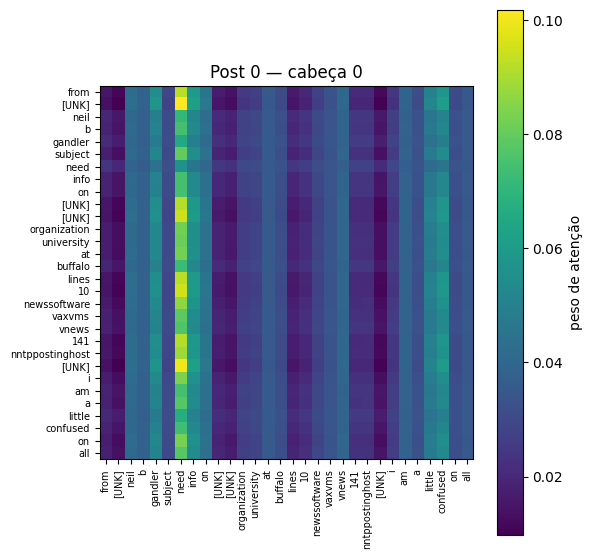

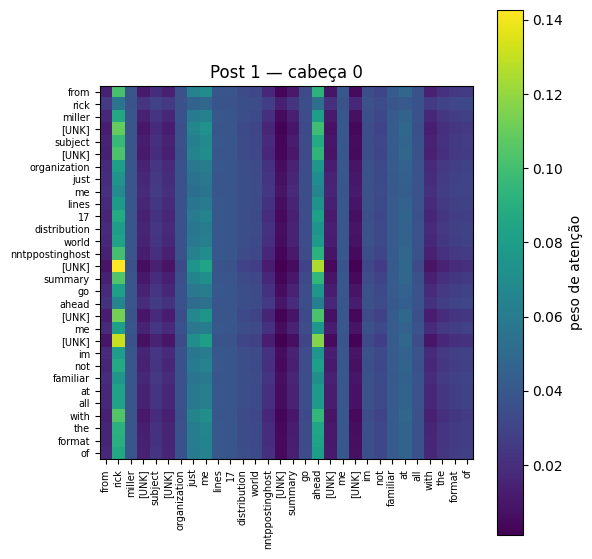

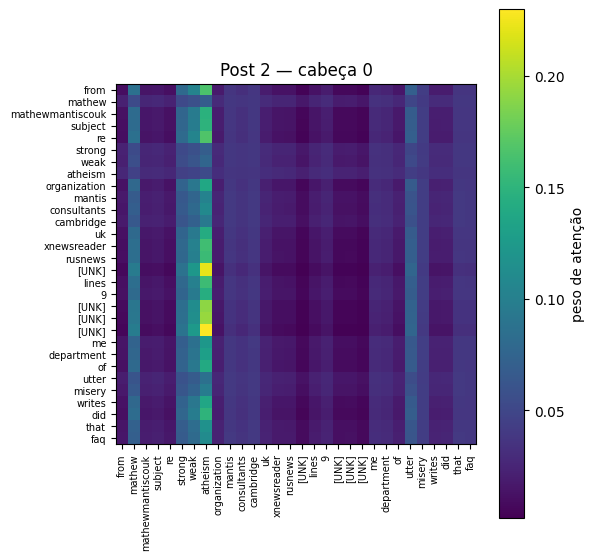

In [25]:
for i in posts:
  mostrar_atencao(model, i, 0)

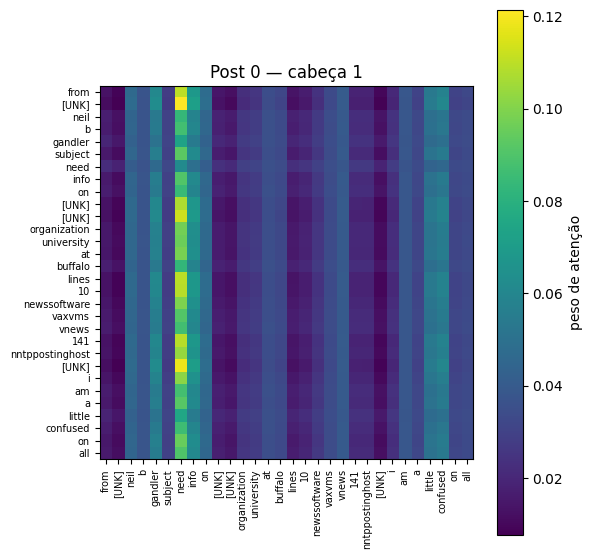

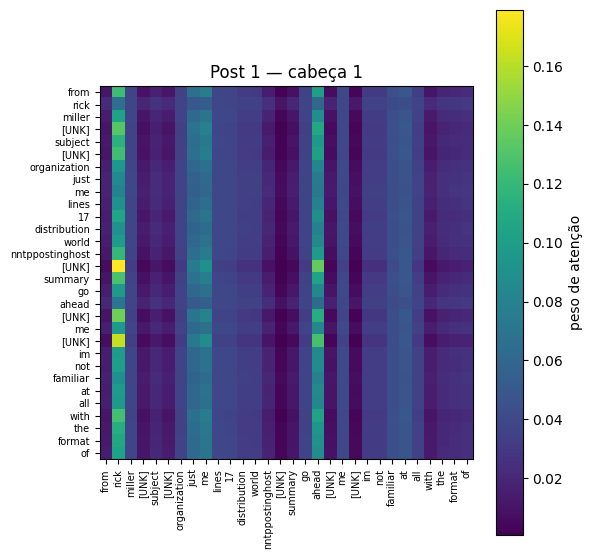

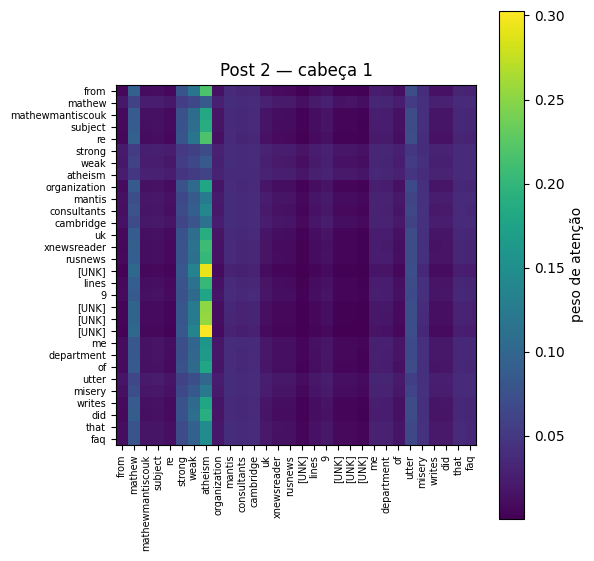

In [26]:
for i in posts:
  mostrar_atencao(model, i, 1)

há linhas de atenção visível, indicando palavras chave, assim como o exercício 2 indicou, isso ocorre nas duas cabeças. as cores são bem parecidas, assim como sua distrubuição entre as cabeças. elas praticamente tomam uma coluna só. mas, o interessante que ele acha várias colunas / palavras com mais correlação nos erros do que nos acertos de forma bem visível... porem, no com acerto, tem uma coluna com porcentagens bem alta e as demais com menores, como se ele tivesse uma certeza bem maior, e quando tem vários com chances parecidas, erra. isso faz total sentido. comparando post 0 e 2, ambos, nas duas cabeças, tem uma coluna clara de maior atenção, mas o erro (0) tem algumas colunas a mais com atenção um pouco maior em comparaçãop com o 2. não sei exatamente oq minha observação indica e se tem fundamento, mas é algo notável visualmente. as cabeças tem padrões parecidos, mas têm atenções diferentes olhando bem. obs: um a coluna vertical indica várias queries apontando pra uma mesma key, isso explica mais ainda a palavra chave; vale ressaltar que analisei apenas 3 posts, e isso é a matriz de atenção, antes de ser multiplicada pelos values e passar pelo softmax. e apresentei evidências, nao considero a distribuição das colunas causa de erro ou acerto.



---




### **Exercício 5 (extensão, escolha UMA)**
- **(a) Embeddings pré-treinados.** Inicialize a camada de embedding de palavras com os vetores **GloVe** (como na aula da LSTM, 100 dimensões) e compare treinando-a (`trainable=True`) e congelando-a (`trainable=False`).
- **(b) Máscara de padding.** Posts curtos são preenchidos com zeros e a atenção, no código acima, também "olha" para esse padding. Passe uma máscara (`attention_mask`) para o `MultiHeadAttention` e veja se o resultado melhora.
- **(c) Modelo pré-treinado.** Faça *fine-tuning* de um modelo pré-treinado pequeno (por exemplo, DistilBERT via biblioteca `transformers` do Hugging Face) no mesmo problema, com sequências de 128 tokens. Compare com o seu Transformer treinado do zero e discuta a diferença.


In [42]:
class TransformerBlock2(layers.Layer):
    """Self-attention + feed-forward, cada um com residual e LayerNorm."""
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att  = layers.MultiHeadAttention(num_heads=num_heads,
                                              key_dim=embed_dim // num_heads)
        self.ffn  = keras.Sequential([layers.Dense(ff_dim, activation="relu"),
                                      layers.Dense(embed_dim)])
        self.ln1  = layers.LayerNormalization(epsilon=1e-6)
        self.ln2  = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(rate)
        self.drop2 = layers.Dropout(rate)

    def call(self, x, attention_mask=None, training=False):
        a = self.att(x, x, attention_mask=attention_mask, training=training)          # query = key = value = x
        x = self.ln1(x + self.drop1(a, training=training))
        f = self.ffn(x, training=training)

        return self.ln2(x + self.drop2(f, training=training))

In [54]:

inputs = keras.Input(shape=(200,), dtype="int32")

pad_mask = inputs != 0
attn_mask = pad_mask[:, tf.newaxis, tf.newaxis, :]

x = TokenAndPositionEmbedding(200, max_features, embed_dim)(inputs)
x = TransformerBlock2(embed_dim, num_heads, ff_dim)(x, attention_mask=attn_mask)
x = layers.GlobalAveragePooling1D()(x)     # média sobre as posições
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(20, activation="softmax")(x)

model_pad = keras.Model(inputs, outputs)
model_pad.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_8         │ (None, 200)       │          0 │ input_layer_16[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, 200, 32)   │    646,400 │ input_layer_16[0… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 1, 1, 200) │          0 │ not_equal_8[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block2… │ (None, 200, 32)   │      8,544 │ token_and_positi… │
│ (TransformerBlock2) │                   │            │ get_item_7[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_35          │ (None, 32)        │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 20)        │        660 │ dropout_35[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 655,604 (2.50 MB)

 Trainable params: 655,604 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

In [57]:
x_train_p = vetorizar_em_lotes(
      vectorizer, newsgroups_train.data, 200, max_features
)
x_test_p = vetorizar_em_lotes(
      vectorizer, newsgroups_test.data, 200, max_features
)


model_pad.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              metrics=["accuracy"])

t0 = time.time()
history = model_pad.fit(x_train_p, y_train,
                    batch_size=batch_size,
                    epochs=10,
                    validation_data=(x_test_p, y_test))
print(f"Tempo de treino: {time.time() - t0:.0f}s")

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step - accuracy: 0.4476 - loss: 1.9343 - val_accuracy: 0.7307 - val_loss: 0.9532
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9045 - loss: 0.3790 - val_accuracy: 0.8155 - val_loss: 0.6844
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9768 - loss: 0.1102 - val_accuracy: 0.8270 - val_loss: 0.7066
Epoch 4/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9935 - loss: 0.0377 - val_accuracy: 0.8266 - val_loss: 0.7285
Epoch 5/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9977 - loss: 0.0185 - val_accuracy: 0.8322 - val_loss: 0.7681
Epoch 6/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9987 - loss: 0.0109 - val_accuracy: 0.8328 - val_loss: 0.8053
Epoch 7/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9984 - loss: 0.0081 - val_accuracy: 0.8334 - val_loss: 0.8400
Epoch 8/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9991 - loss: 0.0063 - val_accuracy: 

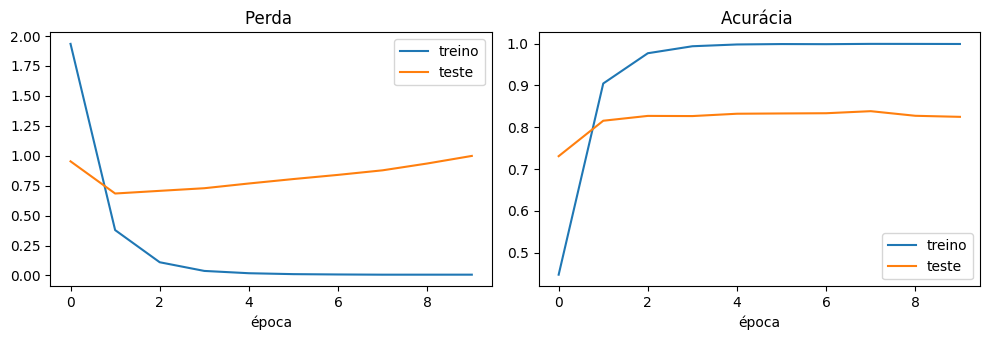

In [58]:
plot_history(history)

In [60]:
loss, acc = model_pad.evaluate(x_test_p, y_test)
print(f'Loss: {loss} | Acurácia: {acc}')

236/236 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8247 - loss: 0.9984
Loss: 0.9983507990837097 | Acurácia: 0.8247477412223816


o resultado ficou extremamente similar. talvez os posts tenham tamanho suficiente pra que não precise de tanto padding, ou o treinamento padrão já consegue aprender bem como lidar com o padding. claro, isso foi com seq_lenght 30, vou tentar com um maior ( isso já dá ganho naturalmente, vou por 200 e comparar com o resultado do exercicio 3 ). ficou extremamanete parecido também. pelo visto o modelo já lida bem com o padding naturalmente.



---



### **Pergunta final.** Em 5 a 8 linhas: o que você aprendeu sobre as diferenças entre RNN/LSTM e Transformer neste problema (custo, paralelização, desempenho, interpretabilidade)? Em que situações você escolheria cada um?

transformers têm uma capacidade maior de reter contexto de forma natural em relação as rnns e lstms, e ainda mais considerando sequencias de grande extensão. além disso, o treino dos transformers permite paralelização entre as cabeças, o que permite maior velocidade. com modelos de parâmetros parecidos, com tempos de treino também parecidos, os transformers se monstram bem superiores. sobre a interpretabilidade, não há muita em modelos de deep learning em geral, mas conseguimos analisar a matriz de atenção de transformers, e não há nada equivalente em rnn e lstm. sendo sincero, não vejo o que rnns e lstms fariam que transformers não fariam melhor, talvez tarefas mais simples, menor recursos computacionais possam se adequar melhor com esses modelos, pois transformers, como visto, nesses casos pode dar overffiting e pode escalar muito a matriz de atenção.